<a href="https://colab.research.google.com/github/Chlo3Cook/spike-simulator-MAC/blob/main/Neural_voltage_fit_and_generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural voltage recording: fit, test, and generate

This notebook fits a compact model to `spike_data.npz` using **NumPy + Matplotlib only**.

**What it does**
1. Uploads `spike_data.npz` (`t` and `raw_data`).
2. Removes the slow baseline with a 101 ms running median and detects spikes at 8 robust standard deviations.
3. Fits the sine drift and exponential spike shape on **0–7 s**, then evaluates on **7–10 s**.
4. Refits the final model on all 10 s and prints parameter estimates, uncertainties, detection metrics, and residual checks.
5. Draws the requested plots and defines `generate_signal(duration_s, seed)`.

**Important about the test:** the test-segment spike onsets are detected from the recording and supplied to the reconstruction. Therefore, the 7–10 s test measures whether the *fitted drift and spike waveform* generalize; it does not claim to predict the random timing of unseen spikes.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 1. Imports and upload the NPZ file
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from pathlib import Path

try:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No file was uploaded. Upload spike_data.npz and rerun this cell.")
    DATA_PATH = next(iter(uploaded.keys()))
except ImportError:
    # For local Jupyter, put spike_data.npz beside this notebook.
    DATA_PATH = "/content/drive/MyDrive/python/spike_data (2).npz"

print("Using file:", DATA_PATH)

Saving spike_data (2).npz to spike_data (2).npz
Using file: spike_data (2).npz


In [ ]:
# 2. Helper functions: running median, sine fit, exponential-spike fit
def running_median(x, width=101):
    """Centered running median with reflected edge padding."""
    if width % 2 != 1:
        raise ValueError("width must be odd")
    p = width // 2
    xp = np.pad(np.asarray(x, float), (p, p), mode="reflect")
    return np.median(sliding_window_view(xp, width), axis=-1)

def fit_sine(t, y, valid):
    """Grid-search frequency; at each frequency solve c + a*sin + b*cos by LS."""
    tv, yv = t[valid], y[valid]
    def search(freqs):
        best = (np.inf, None, None)
        for f0 in freqs:
            ang = 2*np.pi*f0*tv
            X = np.column_stack((np.ones(tv.size), np.sin(ang), np.cos(ang)))
            beta = np.linalg.lstsq(X, yv, rcond=None)[0]
            err = yv - X @ beta
            mse = float(np.mean(err**2))
            if mse < best[0]:
                best = (mse, float(f0), beta)
        return best
    coarse = search(np.arange(0.05, 0.1400001, 0.00005))
    fine_lo = max(0.05, coarse[1] - 0.00015)
    fine_hi = min(0.14, coarse[1] + 0.0001501)
    return search(np.arange(fine_lo, fine_hi, 0.000001))

def sine_value(t, f, beta):
    return beta[0] + beta[1]*np.sin(2*np.pi*f*t) + beta[2]*np.cos(2*np.pi*f*t)

def fit_exponential_spikes(t, y_after_drift, event_times, fit_mask):
    """Grid-search tau; solve the shared amplitude A by linear least squares."""
    age = t[:, None] - event_times[None, :]
    yy = y_after_drift[fit_mask]
    best = (np.inf, None, None)
    for tau in np.arange(0.0020, 0.0045001, 0.000001):
        kernels = np.exp(-np.maximum(age, 0)/tau) * (age >= 0)
        summed = kernels.sum(axis=1)
        xx = summed[fit_mask]
        denom = np.dot(xx, xx)
        A = np.dot(xx, yy) / denom if denom else 0.0
        mse = float(np.mean((yy - A*xx)**2))
        if mse < best[0]:
            best = (mse, float(tau), float(A))
    return best

def signal_scores(y, pred):
    err = y - pred
    return {
        "R2": float(1 - np.sum(err**2)/np.sum((y-y.mean())**2)),
        "RMSE": float(np.sqrt(np.mean(err**2))),
        "MAE": float(np.mean(np.abs(err))),
    }

def rank_auc(labels, scores):
    """AUC from ranks; no scikit-learn required."""
    labels = np.asarray(labels, bool)
    scores = np.asarray(scores, float)
    order = np.argsort(scores)
    ranks = np.empty(len(scores), float)
    ranks[order] = np.arange(1, len(scores)+1)
    n_pos = int(labels.sum()); n_neg = len(labels)-n_pos
    if n_pos == 0 or n_neg == 0:
        return np.nan
    return float((ranks[labels].sum() - n_pos*(n_pos+1)/2)/(n_pos*n_neg))

print("Helper functions ready.")

Helper functions ready.


In [ ]:
# 3. Load data, detrend for detection, and find spike onsets
data = np.load(DATA_PATH)
t = np.asarray(data["t"], dtype=float)
y = np.asarray(data["raw_data"], dtype=float)
if t.ndim != 1 or y.ndim != 1 or t.shape != y.shape:
    raise ValueError("Expected matching one-dimensional arrays named 't' and 'raw_data'.")
dt = float(np.median(np.diff(t)))
fs = 1.0/dt
duration_s = float(t[-1] + dt)

# Detection baseline: 101 ms running median.
baseline_median = running_median(y, 101)
detrended = y - baseline_median
sigma_detect = float(np.median(np.abs(detrended - np.median(detrended))) / 0.6745)
threshold = 8*sigma_detect
above = detrended > threshold
onset_indices = np.where(above & ~np.r_[False, above[:-1]])[0]
events = t[onset_indices]

# Reference onsets supplied with the task; used only to score detection.
reference_events = np.array([
    0.195, 0.322, 0.388, 0.414, 0.444, 0.647, 1.421, 1.719, 1.751, 1.855,
    2.066, 2.312, 2.399, 2.446, 2.481, 2.729, 2.941, 2.996, 3.449, 4.636,
    4.652, 4.693, 4.756, 5.057, 5.083, 5.331, 5.721, 5.732, 5.873, 5.964,
    6.527, 6.599, 7.095, 7.130, 7.353, 7.629, 7.980, 8.653, 8.666, 9.408,
    9.624, 9.793
], dtype=float)

print(f"Samples: {len(t):,}; sampling rate: {fs:.1f} Hz; duration: {duration_s:.3f} s")
print(f"Robust detection sigma: {sigma_detect:.4f}; 8-sigma threshold: {threshold:.4f}")
print(f"Detected {len(events)} spike onsets:")
print(np.array2string(events, precision=3, separator=", "))

Samples: 10,000; sampling rate: 1000.0 Hz; duration: 10.000 s
Robust detection sigma: 0.3073; 8-sigma threshold: 2.4585
Detected 42 spike onsets:
[0.195, 0.322, 0.388, 0.414, 0.444, 0.647, 1.421, 1.719, 1.751, 1.855,
 2.066, 2.312, 2.399, 2.446, 2.481, 2.729, 2.941, 2.996, 3.449, 4.636,
 4.652, 4.693, 4.756, 5.057, 5.083, 5.331, 5.721, 5.732, 5.873, 5.964,
 6.527, 6.599, 7.095, 7.13 , 7.353, 7.629, 7.98 , 8.653, 8.666, 9.408,
 9.624, 9.793]


In [ ]:
# 4. Train on 0-7 s; test on 7-10 s; then refit on all 10 s
train_mask = t < 7.0
test_mask = (t >= 7.0) & (t < 10.0)

# Keep the large spike transients out of the slow-drift fit.
exclude_spikes = np.zeros(t.size, dtype=bool)
for idx in onset_indices:
    exclude_spikes[max(0, idx-2):min(t.size, idx+35)] = True

# TRAIN: fit one sine to 0-7 s only.
_, f_train, beta_train = fit_sine(t, y, train_mask & ~exclude_spikes)
drift_train = sine_value(t, f_train, beta_train)
train_events = events[events < 7.0]
_, tau_train, A_train = fit_exponential_spikes(
    t, y-drift_train, train_events, train_mask
)

# Reconstruct the full trace using TRAINED parameters. For the holdout, detected
# holdout onsets are supplied so that the test is about waveform/drift fit only.
ages_all_train = t[:, None] - events[None, :]
K_train = np.exp(-np.maximum(ages_all_train, 0)/tau_train) * (ages_all_train >= 0)
pred_train_model = drift_train + A_train*K_train.sum(axis=1)
train_scores = signal_scores(y[train_mask], pred_train_model[train_mask])
test_scores = signal_scores(y[test_mask], pred_train_model[test_mask])

# Drift forecast error compared to the running-median baseline proxy on 7-10 s.
drift_test_rmse = float(np.sqrt(np.mean((drift_train[test_mask]-baseline_median[test_mask])**2)))
drift_test_mae = float(np.mean(np.abs(drift_train[test_mask]-baseline_median[test_mask])))

# REFIT: fit drift and spike shape on the full 10 s.
_, f_all, beta_all = fit_sine(t, y, ~exclude_spikes)
drift_all = sine_value(t, f_all, beta_all)
_, tau_all, A_all = fit_exponential_spikes(
    t, y-drift_all, events, np.ones(t.size, dtype=bool)
)
ages_all = t[:, None] - events[None, :]
K_all = np.exp(-np.maximum(ages_all, 0)/tau_all) * (ages_all >= 0)
spike_component = A_all*K_all.sum(axis=1)
fitted_noise_free = drift_all + spike_component
residual = y - fitted_noise_free
final_scores = signal_scores(y, fitted_noise_free)
sigma_resid = float(np.std(residual, ddof=1))
sigma_resid_mad = float(np.median(np.abs(residual-np.median(residual)))/0.6745)

# Convert c + a*sin(wt) + b*cos(wt) to B*sin(wt + phi).
c, a_sin, b_cos = beta_all
B = float(np.hypot(a_sin, b_cos))
phi = float(np.arctan2(b_cos, a_sin))
f = float(f_all)

print("TRAINED ON 0-7 s")
print(f"c={beta_train[0]:.6f}, f={f_train:.6f} Hz, A={A_train:.4f}, tau={tau_train*1000:.4f} ms")
print("Train scores:", train_scores)
print("Holdout 7-10 s scores:", test_scores)
print(f"Holdout drift RMSE={drift_test_rmse:.4f}, MAE={drift_test_mae:.4f} (vs running-median baseline)")
print("\nREFIT ON ALL 10 s")
print(f"c={c:.6f}, B={B:.6f}, f={f:.6f} Hz, phi={phi:.6f} rad")
print(f"A={A_all:.6f}, tau={tau_all*1000:.4f} ms, sigma={sigma_resid:.6f}")
print("All-data scores:", final_scores)

TRAINED ON 0-7 s
c=0.011518, f=0.092068 Hz, A=4.9936, tau=2.9700 ms
Train scores: {'R2': 0.8117586658022125, 'RMSE': 0.29953373555171886, 'MAE': 0.238586530887743}
Holdout 7-10 s scores: {'R2': 0.684749548422801, 'RMSE': 0.29707298963296297, 'MAE': 0.23892756682696903}
Holdout drift RMSE=0.0500, MAE=0.0418 (vs running-median baseline)

REFIT ON ALL 10 s
c=0.003002, B=0.648357, f=0.090823 Hz, phi=0.286174 rad
A=5.016163, tau=2.9820 ms, sigma=0.298455
All-data scores: {'R2': 0.8348642510384976, 'RMSE': 0.29843983277881053, 'MAE': 0.23821956826912793}


In [ ]:
# 5. Parameter uncertainty (approx. 95% intervals) and duration to noise level
# Conditional least-squares covariance: uncertainty assumes detected onsets are fixed.
valid = ~exclude_spikes
ang = 2*np.pi*f*t
rbase = y[valid] - drift_all[valid]
J_drift = np.column_stack((
    np.ones(valid.sum()),
    np.sin(ang[valid]),
    np.cos(ang[valid]),
    2*np.pi*t[valid]*(a_sin*np.cos(ang[valid])-b_cos*np.sin(ang[valid]))
))
var_drift = np.sum(rbase**2)/(valid.sum()-4)
cov_drift = var_drift*np.linalg.inv(J_drift.T@J_drift)
se_drift = np.sqrt(np.diag(cov_drift))
gB = np.array([0.0, a_sin/B, b_cos/B, 0.0])
gphi = np.array([0.0, -b_cos/B**2, a_sin/B**2, 0.0])
se_B = float(np.sqrt(gB@cov_drift@gB))
se_phi = float(np.sqrt(gphi@cov_drift@gphi))

Ksum = K_all.sum(axis=1)
d_tau = A_all*np.sum(
    np.exp(-np.maximum(ages_all,0)/tau_all)*(ages_all>=0)
    *np.maximum(ages_all,0)/tau_all**2, axis=1
)
J_spike = np.column_stack((Ksum, d_tau))
cov_spike = (np.sum(residual**2)/(len(t)-6))*np.linalg.inv(J_spike.T@J_spike)
se_A, se_tau = np.sqrt(np.diag(cov_spike))
se_sigma = sigma_resid/np.sqrt(2*(len(t)-6))

# Delta-method uncertainty for duration = tau * ln(A/sigma).
duration_ms = tau_all*np.log(A_all/sigma_resid)*1000
grad = np.array([tau_all/A_all, np.log(A_all/sigma_resid), -tau_all/sigma_resid])
var_duration = (grad[0]**2*se_A**2 + grad[1]**2*se_tau**2 + grad[2]**2*se_sigma**2)
se_duration_ms = float(np.sqrt(var_duration)*1000)

parameter_rows = [
    ("Sampling rate", f"{fs:.1f} Hz", "from time vector", "KEEP", "1 ms sample interval"),
    ("c", f"{c:.6f} ± {1.96*se_drift[0]:.6f}", "95% approx.", "KEEP", "drift offset"),
    ("B", f"{B:.6f} ± {1.96*se_B:.6f}", "95% approx.", "KEEP", "drift amplitude"),
    ("f", f"{f:.6f} ± {1.96*se_drift[3]:.6f} Hz", "95% approx.", "KEEP, CAUTION", "less than one fitted period is observed"),
    ("phi", f"{phi:.6f} ± {1.96*se_phi:.6f} rad", "95% approx.", "KEEP", "drift phase"),
    ("A", f"{A_all:.6f} ± {1.96*se_A:.6f}", "95% approx.", "KEEP", "shared spike height at onset"),
    ("tau", f"{tau_all*1000:.4f} ± {1.96*se_tau*1000:.4f} ms", "95% approx.", "KEEP", "exponential decay"),
    ("sigma", f"{sigma_resid:.6f} ± {1.96*se_sigma:.6f}", "95% approx.", "KEEP", "noise SD from residual"),
    ("Spike duration", f"{duration_ms:.2f} ± {1.96*se_duration_ms:.2f} ms", "95% approx.", "DERIVED", "time for exponential to fall to 1 sigma"),
    ("Spike onsets", f"{len(events)} events", "±0.5 ms sample quantization", "KEEP", "detected first sample above threshold"),
    ("Spike rate", f"{len(events)/duration_s:.2f} Hz", "Poisson approx. 95%: 3.0–5.7 Hz", "KEEP", "42 events in 10 s"),
    ("Counting window W", "0.5 s", "20 bins across 10 s", "KEEP", "compromise between local timing detail and count complexity"),
]
print("PARAMETER TABLE")
for row in parameter_rows:
    print(f"{row[0]:<18} {row[1]:<30} {row[3]:<13} {row[4]}")
print(f"\nSpike duration to noise level: {duration_ms:.2f} ± {1.96*se_duration_ms:.2f} ms")

PARAMETER TABLE
Sampling rate      1000.0 Hz                      KEEP          1 ms sample interval
c                  0.003002 ± 0.006416            KEEP          drift offset
B                  0.648357 ± 0.008969            KEEP          drift amplitude
f                  0.090823 ± 0.000853 Hz         KEEP, CAUTION less than one fitted period is observed
phi                0.286174 ± 0.030794 rad        KEEP          drift phase
A                  5.016163 ± 0.077826            KEEP          shared spike height at onset
tau                2.9820 ± 0.0764 ms             KEEP          exponential decay
sigma              0.298455 ± 0.004138            KEEP          noise SD from residual
Spike duration     8.41 ± 0.22 ms                 DERIVED       time for exponential to fall to 1 sigma
Spike onsets       42 events                      KEEP          detected first sample above threshold
Spike rate         4.20 Hz                        KEEP          42 events in 10 s
Counting win

In [ ]:
# 6. Spike detection scores (event-wise and sample-wise, ±2 ms tolerance)
# Event-wise one-to-one matching.
used_ref = np.zeros(len(reference_events), dtype=bool)
event_tp = 0
for detected in events:
    candidates = np.where((np.abs(reference_events-detected) <= 0.002) & ~used_ref)[0]
    if candidates.size:
        j = candidates[np.argmin(np.abs(reference_events[candidates]-detected))]
        used_ref[j] = True
        event_tp += 1
event_fp = len(events)-event_tp
event_fn = len(reference_events)-event_tp
event_precision = event_tp/(event_tp+event_fp) if event_tp+event_fp else 0.0
event_recall = event_tp/(event_tp+event_fn) if event_tp+event_fn else 0.0
event_f1 = 2*event_precision*event_recall/(event_precision+event_recall) if event_precision+event_recall else 0.0

# Sample-wise labels: positive if within +/-2 ms of a reference onset.
truth_samples = np.zeros(len(t), dtype=bool)
for onset in reference_events:
    ix = int(round(onset/dt))
    truth_samples[max(0,ix-2):min(len(t),ix+3)] = True
pred_samples = above
TP = int(np.sum(truth_samples & pred_samples))
FP = int(np.sum(~truth_samples & pred_samples))
FN = int(np.sum(truth_samples & ~pred_samples))
TN = int(np.sum(~truth_samples & ~pred_samples))
precision = TP/(TP+FP) if TP+FP else 0.0
recall = TP/(TP+FN) if TP+FN else 0.0
f1_sample = 2*precision*recall/(precision+recall) if precision+recall else 0.0
specificity = TN/(TN+FP) if TN+FP else 0.0
balanced_accuracy = (recall+specificity)/2
denominator = np.sqrt((TP+FP)*(TP+FN)*(TN+FP)*(TN+FN))
mcc = (TP*TN-FP*FN)/denominator if denominator else 0.0
auc = rank_auc(truth_samples, detrended)

print("EVENT-LEVEL (onsets matched within ±2 ms)")
print(f"Precision={event_precision:.3f}  Recall={event_recall:.3f}  F1={event_f1:.3f}")
print("SAMPLE-LEVEL (positive samples within ±2 ms)")
print(f"Precision={precision:.3f}  Recall={recall:.3f}  F1={f1_sample:.3f}")
print(f"Balanced accuracy={balanced_accuracy:.3f}  MCC={mcc:.3f}  AUC={auc:.3f}")
print("Note: event-wise and sample-wise scores answer different questions; sample recall can be lower even when every event onset is detected.")

# Counts and interspike intervals.
counts_1s, _ = np.histogram(events, bins=np.arange(0, duration_s+1, 1.0))
gaps_ms = np.diff(events)*1000
print("\n1-second spike counts:", counts_1s.tolist())
print(f"Total={len(events)}, rate={len(events)/duration_s:.2f} Hz, minimum gap={gaps_ms.min():.1f} ms")

EVENT-LEVEL (onsets matched within ±2 ms)
Precision=1.000  Recall=1.000  F1=1.000
SAMPLE-LEVEL (positive samples within ±2 ms)
Precision=0.972  Recall=0.505  F1=0.665
Balanced accuracy=0.752  MCC=0.697  AUC=0.758
Note: event-wise and sample-wise scores answer different questions; sample recall can be lower even when every event onset is detected.

1-second spike counts: [6, 4, 8, 1, 4, 7, 2, 5, 2, 3]
Total=42, rate=4.20 Hz, minimum gap=11.0 ms


In [ ]:
# 7. Residual diagnostics: white-noise and normality checks
z = (residual-residual.mean())/sigma_resid
skew = float(np.mean(z**3))
excess_kurtosis = float(np.mean(z**4)-3)
acf = {}
for lag in [1,2,3,5,10,20,50,100]:
    acf[lag] = float(np.corrcoef(residual[:-lag], residual[lag:])[0,1])
acf_20 = np.array([np.corrcoef(residual[:-lag], residual[lag:])[0,1] for lag in range(1,21)])
ljung_box_q20 = float(len(t)*(len(t)+2)*np.sum(acf_20**2/(len(t)-np.arange(1,21))))
jarque_bera = float(len(t)/6*(skew**2+excess_kurtosis**2/4))

print(f"Residual SD={sigma_resid:.4f}; MAD sigma={sigma_resid_mad:.4f}")
print(f"Skewness={skew:.3f}; excess kurtosis={excess_kurtosis:.3f}; JB={jarque_bera:.2f}")
print("Residual autocorrelations:", {k: round(v,4) for k,v in acf.items()})
print(f"Ljung-Box Q(20)={ljung_box_q20:.2f}; approximate 5% cutoff for 20 df is 31.4")
print("Interpretation: values near zero and Q(20) below 31.4 are broadly consistent with white Gaussian residuals; this is a diagnostic, not proof.")

Residual SD=0.2985; MAD sigma=0.2980
Skewness=0.019; excess kurtosis=-0.046; JB=1.50
Residual autocorrelations: {1: -0.0195, 2: -0.0037, 3: -0.0201, 5: 0.0085, 10: -0.0082, 20: 0.0049, 50: 0.0051, 100: 0.0106}
Ljung-Box Q(20)=29.30; approximate 5% cutoff for 20 df is 31.4
Interpretation: values near zero and Q(20) below 31.4 are broadly consistent with white Gaussian residuals; this is a diagnostic, not proof.


In [ ]:
# 8. Counting-window comparison (10 s, 2 s, 1 s, 0.5 s, 0.1 s)
rng = np.random.default_rng(2026)
window_results = []
for W in [10.0, 2.0, 1.0, 0.5, 0.1]:
    edges = np.arange(0, duration_s + W*0.5, W)
    counts, _ = np.histogram(events, bins=edges)
    errors = []
    for _ in range(200):
        sim_times = []
        valid_draw = False
        for _try in range(1000):
            sim_times = []
            for b, n in enumerate(counts):
                if n == 0:
                    continue
                left, right = edges[b], edges[b+1]
                width = right-left
                if width-(n-1)*0.010 < 0:
                    continue
                pos = np.sort(rng.random(n)*(width-(n-1)*0.010)) + np.arange(n)*0.010
                sim_times.extend((left+pos).tolist())
            sim_times = np.sort(sim_times)
            if len(sim_times)<2 or np.min(np.diff(sim_times)) >= 0.010-1e-12:
                valid_draw = True
                break
        if valid_draw and len(sim_times)==len(events):
            errors.append(float(np.mean(np.abs(sim_times-events))))
    window_results.append((W, len(counts), np.mean(errors)*1000 if errors else np.nan,
                           np.quantile(errors,0.05)*1000 if errors else np.nan,
                           np.quantile(errors,0.95)*1000 if errors else np.nan, counts.tolist()))

print("W (s) | count parameters | mean timing difference (ms) | 5–95% range (ms)")
for W,npar,meanerr,q05,q95,counts in window_results:
    print(f"{W:>4.1f} | {npar:>3d} | {meanerr:>7.1f} | {q05:.1f}–{q95:.1f}")
print("\nSuggested W = 0.5 s: 20 bin counts are a reasonable compromise. Smaller windows encode more of this recording but do not predict future event times.")

W (s) | count parameters | mean timing difference (ms) | 5–95% range (ms)
10.0 |   1 |   719.7 | 325.6–1393.9
 2.0 |   5 |   300.4 | 213.1–394.5
 1.0 |  10 |   181.8 | 146.9–220.1
 0.5 |  20 |   121.5 | 95.4–152.9
 0.1 | 100 |    26.4 | 21.6–32.2

Suggested W = 0.5 s: 20 bin counts are a reasonable compromise. Smaller windows encode more of this recording but do not predict future event times.


In [ ]:
# 9. Fit summary table (compact printout)
print("\nSIGNAL SCORES (noise-free fitted formula compared with raw noisy data)")
print("Segment                          R2       RMSE      MAE")
for name, sc in [("0-7 s training", train_scores), ("7-10 s holdout", test_scores), ("0-10 s all-data refit", final_scores)]:
    print(f"{name:<30} {sc['R2']:>7.4f}  {sc['RMSE']:>7.4f}  {sc['MAE']:>7.4f}")
print(f"Noise floor (residual SD): {sigma_resid:.4f}")

print("\nFINAL FITTED FORMULA")
print(f"x(t) = {c:.6f} + {B:.6f}*sin(2*pi*{f:.6f}*t + {phi:.6f})")
print(f"       + sum_k {A_all:.6f}*exp(-(t-t_k)/{tau_all:.6f})*1[t>=t_k] + Normal(0, {sigma_resid:.6f}^2)")
print("All times t and t_k are in seconds; voltage is in arbitrary units.")


SIGNAL SCORES (noise-free fitted formula compared with raw noisy data)
Segment                          R2       RMSE      MAE
0-7 s training                  0.8118   0.2995   0.2386
7-10 s holdout                  0.6847   0.2971   0.2389
0-10 s all-data refit           0.8349   0.2984   0.2382
Noise floor (residual SD): 0.2985

FINAL FITTED FORMULA
x(t) = 0.003002 + 0.648357*sin(2*pi*0.090823*t + 0.286174)
       + sum_k 5.016163*exp(-(t-t_k)/0.002982)*1[t>=t_k] + Normal(0, 0.298455^2)
All times t and t_k are in seconds; voltage is in arbitrary units.


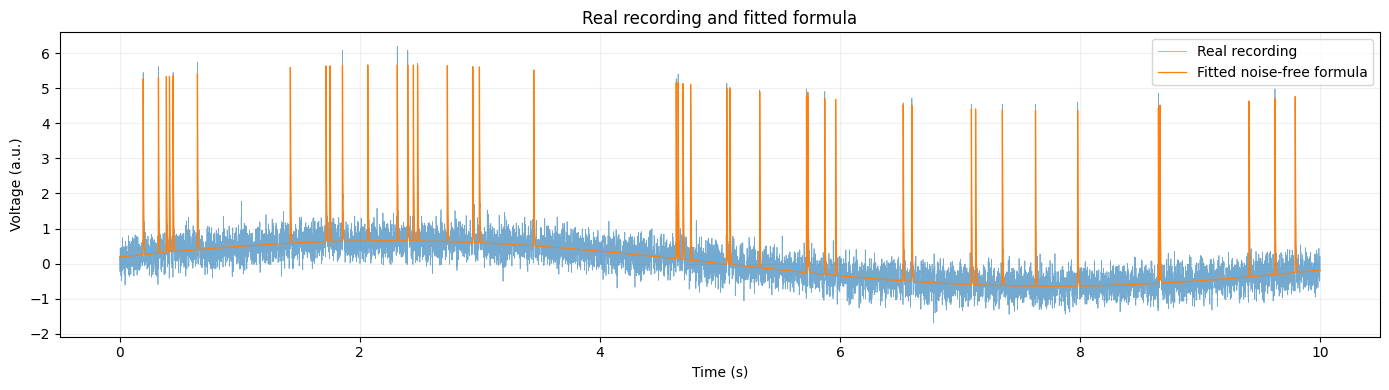

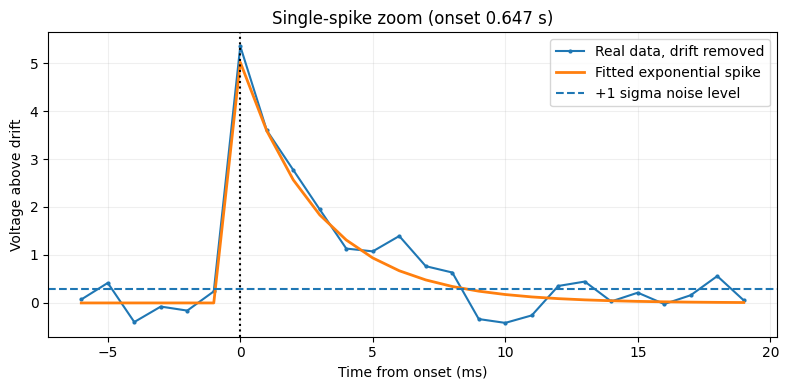

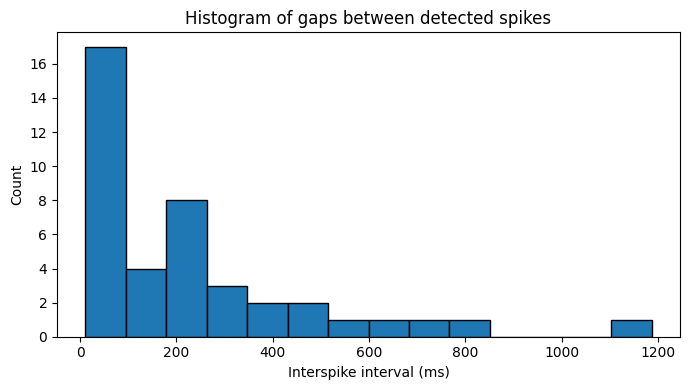

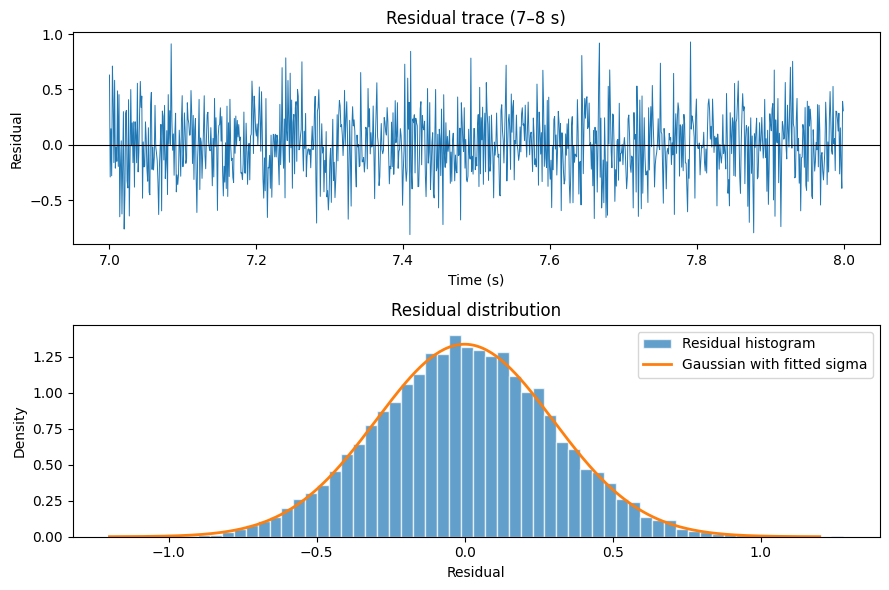

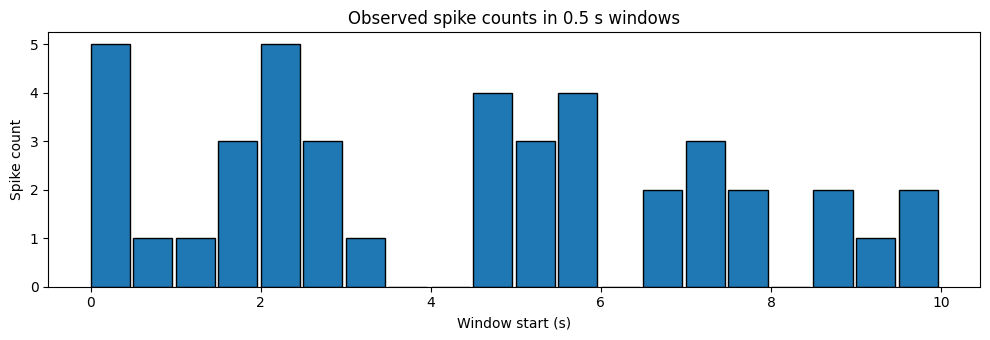

In [ ]:
# 10. Requested plots: full trace, spike zoom, gaps, residual diagnostics, counts
# Plot A: real data vs fitted model and a stochastic generated copy (generator defined below).
fig, ax = plt.subplots(figsize=(14,4))
ax.plot(t, y, lw=0.55, alpha=0.62, label="Real recording")
ax.plot(t, fitted_noise_free, lw=0.9, label="Fitted noise-free formula")
ax.set(xlabel="Time (s)", ylabel="Voltage (a.u.)", title="Real recording and fitted formula")
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

# Plot B: isolated spike around 0.647 s, with fitted drift removed.
onset = events[np.argmin(np.abs(events-0.647))]
ix = int(round(onset/dt))
sl = slice(max(0,ix-6), min(len(t),ix+20))
local_t_ms = (t[sl]-onset)*1000
local_data = y[sl]-drift_all[sl]
local_model = A_all*np.exp(-np.maximum(t[sl]-onset,0)/tau_all)*(t[sl]>=onset)
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(local_t_ms, local_data, ".-", ms=4, label="Real data, drift removed")
ax.plot(local_t_ms, local_model, lw=2, label="Fitted exponential spike")
ax.axhline(sigma_resid, ls="--", label="+1 sigma noise level")
ax.axvline(0, ls=":", color="black")
ax.set(xlabel="Time from onset (ms)", ylabel="Voltage above drift", title=f"Single-spike zoom (onset {onset:.3f} s)")
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

# Plot C: interspike intervals.
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(gaps_ms, bins=14, edgecolor="black")
ax.set(xlabel="Interspike interval (ms)", ylabel="Count", title="Histogram of gaps between detected spikes")
plt.tight_layout(); plt.show()

# Plot D: residual time series and residual distribution.
fig, axes = plt.subplots(2,1,figsize=(9,6))
rmask = (t>=7.0)&(t<8.0)
axes[0].plot(t[rmask], residual[rmask], lw=0.7)
axes[0].axhline(0,color="black",lw=0.8)
axes[0].set(xlabel="Time (s)", ylabel="Residual", title="Residual trace (7–8 s)")
axes[1].hist(residual,bins=60,density=True,alpha=0.7,edgecolor="white",label="Residual histogram")
xx=np.linspace(-1.2,1.2,300)
pdf=np.exp(-0.5*(xx/sigma_resid)**2)/(sigma_resid*np.sqrt(2*np.pi))
axes[1].plot(xx,pdf,lw=2,label="Gaussian with fitted sigma")
axes[1].set(xlabel="Residual",ylabel="Density",title="Residual distribution")
axes[1].legend(); plt.tight_layout(); plt.show()

# Plot E: observed counts in recommended 0.5 s windows.
counts_05, edges_05 = np.histogram(events,bins=np.arange(0,10.0+0.5,0.5))
fig,ax=plt.subplots(figsize=(10,3.5))
ax.bar(edges_05[:-1],counts_05,width=0.46,align="edge",edgecolor="black")
ax.set(xlabel="Window start (s)",ylabel="Spike count",title="Observed spike counts in 0.5 s windows")
plt.tight_layout(); plt.show()

In [ ]:
# 11. A reusable generator: generate_signal(duration_s, seed)
# Uses fitted drift/spike/noise parameters. In the first 10 s it preserves the
# observed counts in 0.5 s bins but randomizes spike positions. After 10 s,
# it generates Poisson counts at the fitted mean rate.
OBSERVED_COUNTS_05S = counts_05.copy()
COUNT_WINDOW_S = 0.5
MIN_SPIKE_GAP_S = 0.010
SPIKE_RATE_HZ = len(events)/duration_s

def _draw_window_times(left, width, count, rng):
    if count <= 0:
        return np.empty(0)
    available = width-(count-1)*MIN_SPIKE_GAP_S
    if available < 0:
        raise ValueError("Requested count cannot fit in window with 10 ms minimum gap")
    pos = np.sort(rng.random(count)*available) + np.arange(count)*MIN_SPIKE_GAP_S
    return left+pos

def _sample_generator_spikes(duration_s, rng):
    n_windows = int(np.ceil(duration_s/COUNT_WINDOW_S))
    for _attempt in range(10000):
        all_events=[]
        for w in range(n_windows):
            left=w*COUNT_WINDOW_S
            width=min(COUNT_WINDOW_S,duration_s-left)
            if width <= 0: continue
            if w < len(OBSERVED_COUNTS_05S):
                # For the observed 10 s interval retain the original count in each bin.
                full_bin_times = _draw_window_times(left, COUNT_WINDOW_S, int(OBSERVED_COUNTS_05S[w]), rng)
                chosen = full_bin_times[full_bin_times < duration_s]
                all_events.extend(chosen.tolist())
            else:
                n=int(rng.poisson(SPIKE_RATE_HZ*width))
                if n and width-(n-1)*MIN_SPIKE_GAP_S < 0:
                    break
                all_events.extend(_draw_window_times(left,width,n,rng).tolist())
        else:
            all_events=np.sort(np.asarray(all_events,float))
            if len(all_events)<2 or np.min(np.diff(all_events)) >= MIN_SPIKE_GAP_S-1e-12:
                return all_events
    raise RuntimeError("Could not draw spike times satisfying the 10 ms gap constraint")

def generate_signal(duration_s, seed=0):
    """Return (time_seconds, voltage) at the fitted 1 kHz sampling rate."""
    if not np.isfinite(duration_s) or duration_s <= 0:
        raise ValueError("duration_s must be a positive finite number")
    rng=np.random.default_rng(seed)
    n=int(np.ceil(duration_s*fs))
    tg=np.arange(n,dtype=float)/fs
    tg=tg[tg<duration_s]
    drift=c+B*np.sin(2*np.pi*f*tg+phi)
    spike_times=_sample_generator_spikes(duration_s,rng)
    spikes=np.zeros_like(tg)
    for tk in spike_times:
        active=tg>=tk
        spikes[active]+=A_all*np.exp(-(tg[active]-tk)/tau_all)
    noise=rng.normal(0,sigma_resid,size=tg.size)
    return tg,drift+spikes+noise

print("Generator is ready. Example call: t_generated, x_generated = generate_signal(10, seed=42)")

Generator is ready. Example call: t_generated, x_generated = generate_signal(10, seed=42)


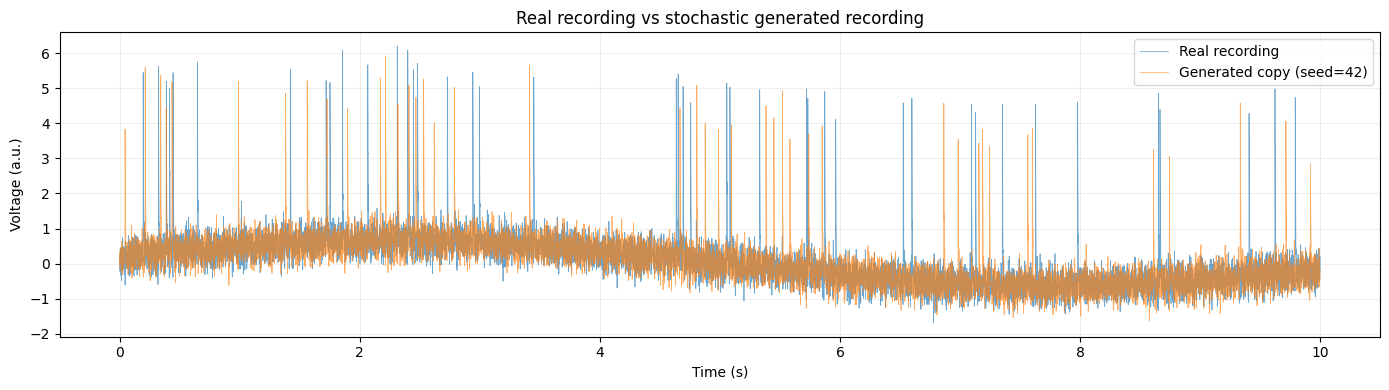

Same seed gives the same synthetic recording: True


In [ ]:
# 12. Generate a stochastic copy and compare it with the real recording
t_generated, x_generated = generate_signal(duration_s=10.0, seed=42)
fig,ax=plt.subplots(figsize=(14,4))
ax.plot(t,y,lw=0.55,alpha=0.65,label="Real recording")
ax.plot(t_generated,x_generated,lw=0.55,alpha=0.65,label="Generated copy (seed=42)")
ax.set(xlabel="Time (s)",ylabel="Voltage (a.u.)",title="Real recording vs stochastic generated recording")
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

print("Same seed gives the same synthetic recording:", np.allclose(x_generated, generate_signal(10.0,seed=42)[1]))

Saving spike_data (2).npz to spike_data (2) (1).npz


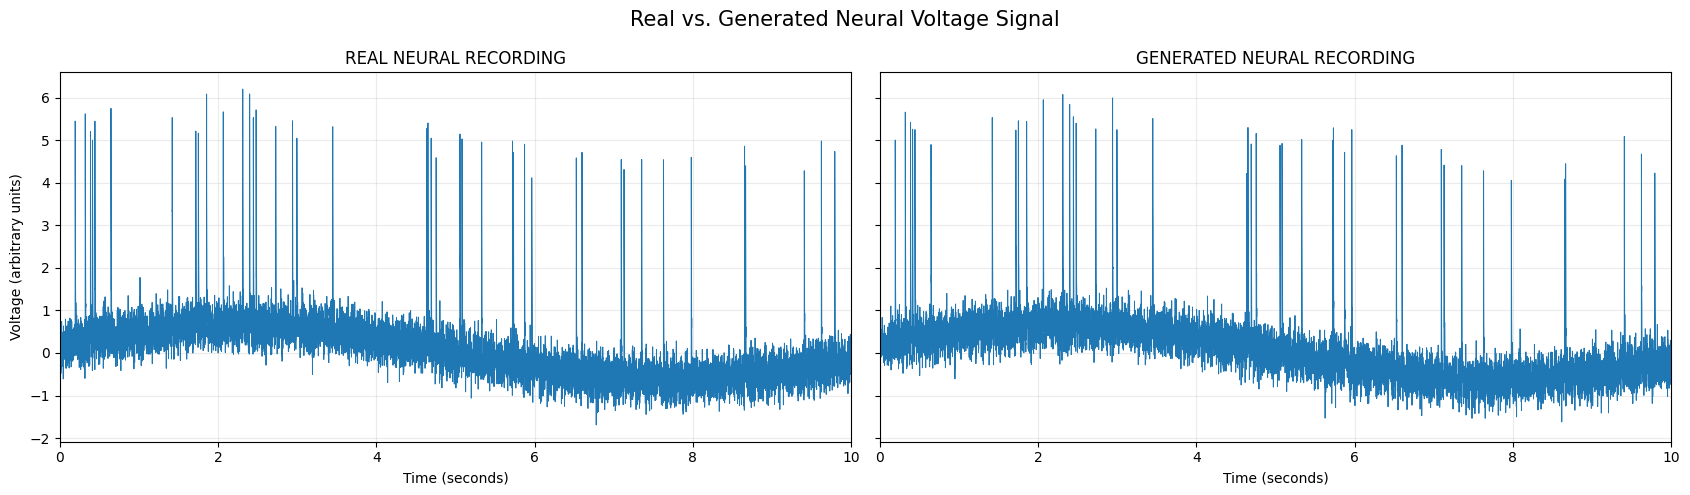

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Fitted model parameters
c = 0.0030
B = 0.6484
f = 0.09082
phi = 0.2861
A = 5.0162
tau = 0.002982
sigma = 0.298

# Detected spike onset times (seconds)
spike_times = np.array([
    0.195, 0.322, 0.388, 0.414, 0.444, 0.647,
    1.421, 1.719, 1.751, 1.855, 2.066, 2.312,
    2.399, 2.446, 2.481, 2.729, 2.941, 2.996,
    3.449, 4.636, 4.652, 4.693, 4.756, 5.057,
    5.083, 5.331, 5.721, 5.732, 5.873, 5.964,
    6.527, 6.599, 7.095, 7.130, 7.353, 7.629,
    7.980, 8.653, 8.666, 9.408, 9.624, 9.793
])

# Load data if t and raw_data are not already defined
# (Use your existing t and raw_data variables otherwise.)
try:
    t, raw_data
except NameError:
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
    data = np.load(filename)
    t = data["t"]
    raw_data = data["raw_data"]

# 1. Generate the slow baseline drift
drift = c + B * np.sin(2 * np.pi * f * t + phi)

# 2. Generate the spikes
spikes = np.zeros_like(t, dtype=float)

for t0 in spike_times:
    mask = t >= t0
    spikes[mask] += A * np.exp(-(t[mask] - t0) / tau)

# 3. Create the complete signal
clean_generated = drift + spikes

# Add independent Gaussian noise
rng = np.random.default_rng(seed=42)
generated = clean_generated + rng.normal(0, sigma, len(t))

# 4. Plot real and generated signals side by side
fig, axes = plt.subplots(
    1, 2, figsize=(17, 5),
    sharey=True
)

axes[0].plot(t, raw_data, linewidth=0.7)
axes[0].set_title("REAL NEURAL RECORDING")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Voltage (arbitrary units)")

axes[1].plot(t, generated, linewidth=0.7)
axes[1].set_title("GENERATED NEURAL RECORDING")
axes[1].set_xlabel("Time (seconds)")

for ax in axes:
    ax.set_xlim(0, 10)
    ax.grid(alpha=0.25)

fig.suptitle("Real vs. Generated Neural Voltage Signal", fontsize=15)
plt.tight_layout()
plt.show()


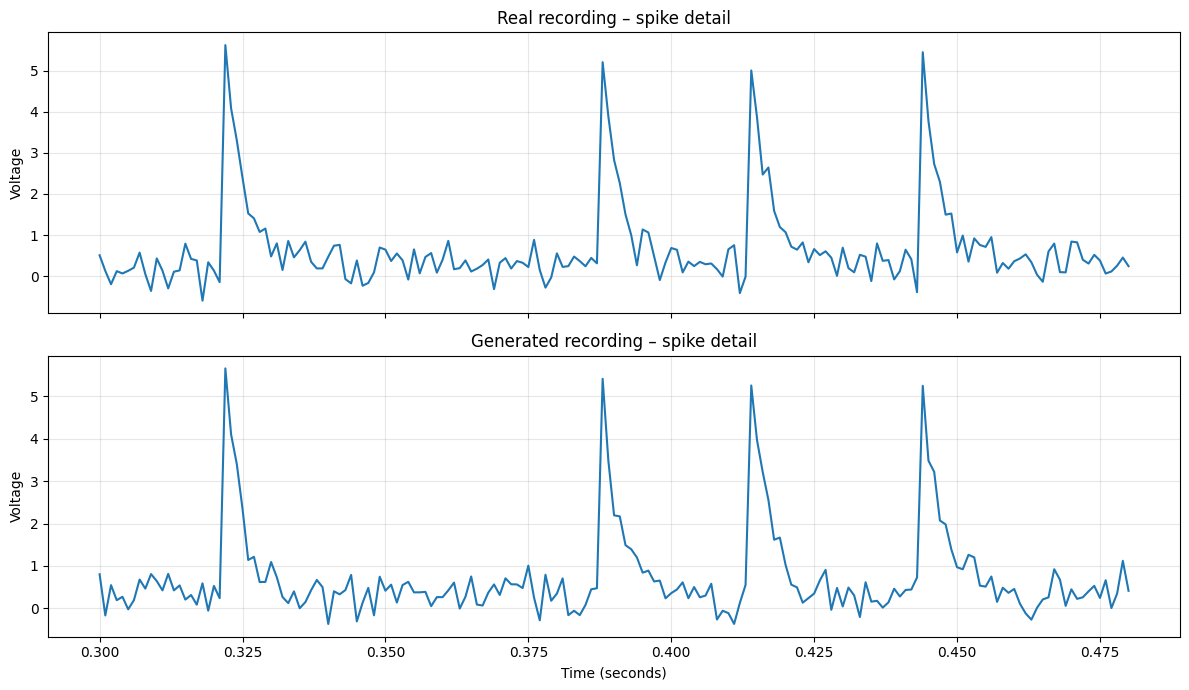

In [ ]:

# Choose a section containing several spikes
start_time = 0.30
end_time = 0.48

mask = (t >= start_time) & (t <= end_time)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(t[mask], raw_data[mask], label="Real signal")
axes[0].set_title("Real recording – spike detail")
axes[0].set_ylabel("Voltage")
axes[0].grid(alpha=0.3)

axes[1].plot(t[mask], generated[mask], label="Generated signal")
axes[1].set_title("Generated recording – spike detail")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Voltage")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


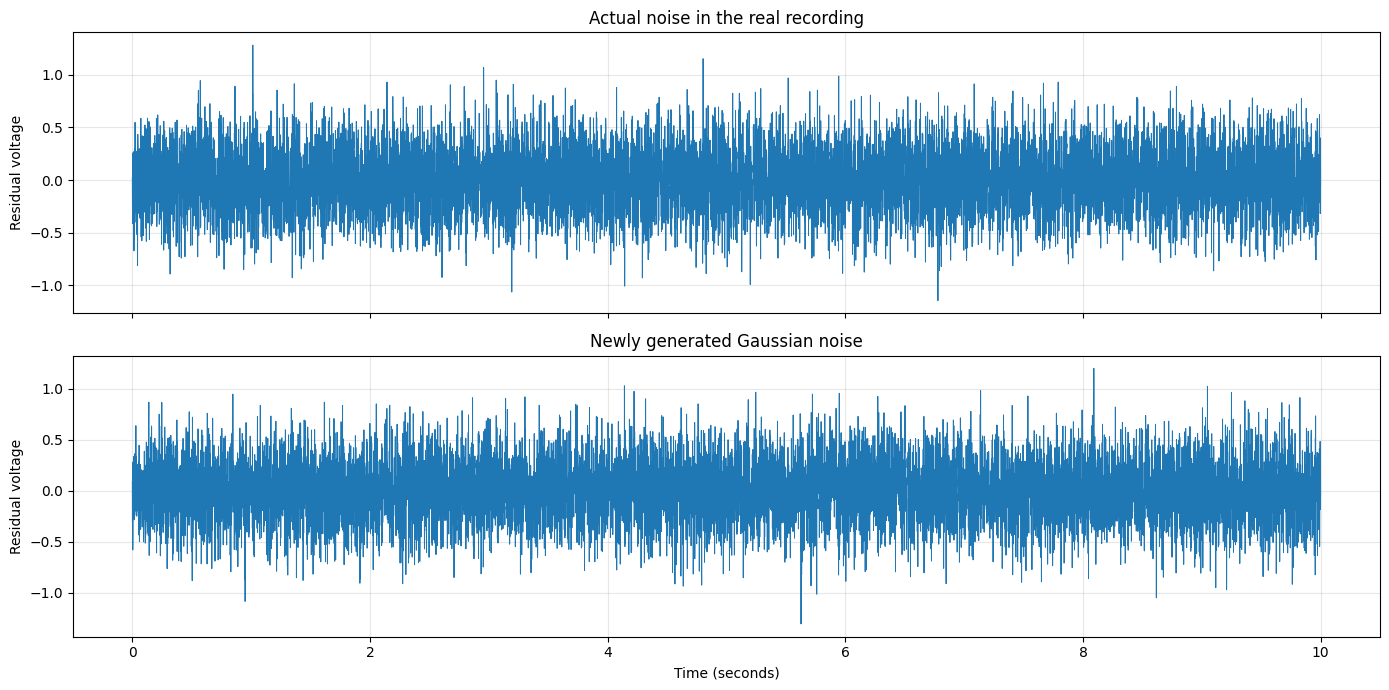

In [ ]:

# Both signals after removing the shared deterministic model

real_residual = raw_data - clean_generated
generated_residual = generated - clean_generated

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(t, real_residual, linewidth=0.7)
axes[0].set_title("Actual noise in the real recording")
axes[0].set_ylabel("Residual voltage")
axes[0].grid(alpha=0.3)

axes[1].plot(t, generated_residual, linewidth=0.7)
axes[1].set_title("Newly generated Gaussian noise")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Residual voltage")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [44]:

import numpy as np
import matplotlib.pyplot as plt

def generate_signal(duration_s=30, seed=42, fs=1000):

    rng = np.random.default_rng(seed)

    # Fitted parameters
    c = 0.0030
    B = 0.6484
    f = 0.09082
    phi = 0.2861

    A = 5.0162
    tau = 0.002982
    sigma = 0.298

    # Firing statistics
    firing_rate = 4.2       # spikes per second
    min_interval = 0.010    # minimum 10 ms between spikes

    # Time vector
    t = np.arange(0, duration_s, 1/fs)

    # 1. Baseline drift
    drift = c + B * np.sin(2*np.pi*f*t + phi)

    # 2. Generate NEW random spike times
    # Shifted exponential intervals:
    # mean interval = 1 / firing_rate
    exp_mean = (1 / firing_rate) - min_interval

    spike_times = []
    current_time = 0.0

    while True:
        current_time += min_interval + rng.exponential(exp_mean)

        if current_time >= duration_s:
            break

        spike_times.append(current_time)

    spike_times = np.array(spike_times)

    # 3. Generate spike waveforms
    spikes = np.zeros(len(t))

    for t0 in spike_times:
        start = np.searchsorted(t, t0)

        if start < len(t):
            spikes[start:] += A * np.exp(
                -(t[start:] - t0) / tau
            )

    # 4. Generate independent Gaussian noise
    noise = rng.normal(0, sigma, len(t))

    # 5. Combine all components
    signal = drift + spikes + noise

    return t, signal, spike_times, drift, spikes, noise


Recording duration: 10.0 seconds
Number of spikes: 33
Firing rate: 1.1 Hz


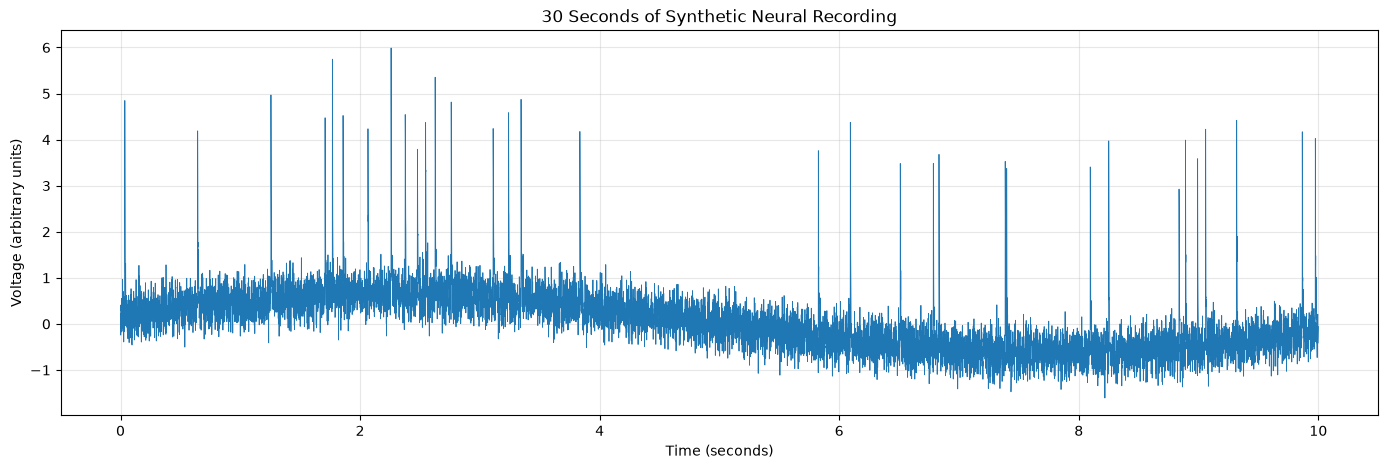

In [48]:

# Generate 30 seconds of new data
t, signal, spike_times, drift, spikes, noise = generate_signal(
    duration_s=10,
    seed=None
)

print("Recording duration:", len(t)/1000, "seconds")
print("Number of spikes:", len(spike_times))
print("Firing rate:", len(spike_times)/30, "Hz")

# Plot entire recording
plt.figure(figsize=(17, 5))
plt.plot(t, signal, linewidth=0.6)
plt.title("30 Seconds of Synthetic Neural Recording")
plt.xlabel("Time (seconds)")
plt.ylabel("Voltage (arbitrary units)")
plt.grid(alpha=0.3)
plt.show()


In [49]:
import numpy as np
np.savez("simulated_spike_data.npz", t=t, raw_data=signal)